# Computational Time Analysis

This notebook measures how long the magnitude-regression models from `AutoML_Hyperparameter_Tuning.ipynb` take to train and to run, and what that time buys in accuracy.

1. **Training time per architecture** - default vs. tuned configurations, then how individual hyperparameters, training-set size and input window length change the cost.
2. **Time vs. accuracy trade-offs** - every configuration timed here on one plot.
3. **Deployment time** - prediction latency, throughput, model size and what they imply for real use.
4. **The final model** - timing of the feature-based HistGradientBoosting selected in `Model_Training_Assessment.ipynb`, including feature extraction and how much waveform it needs.
5. **Conclusion.**

**Setup carried over from the AutoML notebook:** the same data (first 300 samples = 3 s of each 3-component trace, flattened to 900 features), the same split (train on M < 2, test on M >= 2) and the same five architectures with the tuned hyperparameters found there.

**Caveat on accuracy in Sections 2-5.** Each trace is 150 s long and the P arrival is never earlier than sample 5,006 (50 s), so the first 300 samples are pre-event noise. The models in Sections 2-5 therefore time correctly but cannot learn much magnitude information, and their accuracy is close to the mean baseline whatever the configuration. Section 6 times the model that is actually used, which works on features measured around the P and S picks.

**How timing is done here**

- Times are wall-clock seconds from `time.perf_counter()` around `fit` / `predict` only (no data loading).
- Hyperparameter comparisons fit on 80% of the training *events* and score on the other 20% (validation, M < 2, unseen events). The M >= 2 test set is scored too.
- Timings are specific to this machine and change between runs, especially if anything else is using the CPU (close other notebooks/kernels first). The headline table, training-size and window-length results use the median of 3 fits; the hyperparameter sweeps use a single fit each.

In [1]:
import os
import time
import platform
import tempfile
import warnings

import h5py
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from scipy.linalg import LinAlgWarning
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import (RandomForestRegressor,
                              ExtraTreesRegressor,
                              HistGradientBoostingRegressor)
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import GroupShuffleSplit
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Ridge with a small alpha warns that the 900 correlated waveform features are ill-conditioned
warnings.filterwarnings("ignore", category = LinAlgWarning)
warnings.filterwarnings("ignore", category = ConvergenceWarning)

pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:.4g}")

# Hardware / software the timings below were measured on
with open("/proc/cpuinfo") as f:
    cpu_name = next((l.split(":")[1].strip() for l in f if l.startswith("model name")), platform.processor())
with open("/proc/meminfo") as f:
    ram_gb = int(f.readline().split()[1]) / 1e6

N_CORES = os.cpu_count()
print("CPU:", cpu_name)
print("Logical cores:", N_CORES)
print(f"RAM: {ram_gb:.1f} GB")
print("Python:", platform.python_version(), "| scikit-learn:", sklearn.__version__)
print("All models here are scikit-learn CPU models (no GPU is used).")

CPU: AMD Ryzen 5 3600X 6-Core Processor
Logical cores: 12
RAM: 8.1 GB
Python: 3.13.18 | scikit-learn: 1.9.1
All models here are scikit-learn CPU models (no GPU is used).


## 1. Data

Same loading and split as the AutoML notebook. The load itself is timed because reading a trace from disk is part of the cost of making a prediction in deployment.

In [2]:
# Setup paths
repo_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
clean_meta_path = os.path.join(repo_root, "data", "clean", "metadata_clean.parquet")
raw_wave_path = os.path.join(repo_root, "data", "raw", "waveforms.hdf5")

df = pd.read_parquet(clean_meta_path)

N_SAMPLES = 300  # first 3 s of each trace at 100 Hz

load_start = time.perf_counter()
with h5py.File(raw_wave_path, "r") as hf:
    dsets = {k: hf["data"][k] for k in hf["data"]}
    X = np.empty((len(df), 3, N_SAMPLES), dtype = np.float32)
    keep = []
    for b_val, t_idx in zip(df["bucket"], df["tindex"]):
        b_val, t_idx = str(b_val).strip(), int(t_idx)
        b_key = b_val if b_val.startswith("bucket") else f"bucket{b_val}"
        if b_key in dsets and 0 <= t_idx < dsets[b_key].shape[0]:
            X[len(keep)] = dsets[b_key][t_idx, :, :N_SAMPLES]
            keep.append(True)
        else:
            keep.append(False)
load_seconds = time.perf_counter() - load_start

keep = np.array(keep)
X = X[:keep.sum()]
matched_df = df[keep].reset_index(drop = True)
y = matched_df["preferred_source_magnitude"].to_numpy(dtype = np.float32)
groups = matched_df["event_id"].to_numpy()

read_ms_per_trace = 1000 * load_seconds / len(X)

print("Waveform shape:", X.shape)
print(f"Load time: {load_seconds:.1f} s  ({read_ms_per_trace:.2f} ms per trace from HDF5)")

Waveform shape: (18640, 3, 300)
Load time: 52.7 s  (2.83 ms per trace from HDF5)


In [3]:
def flatten(X_wave, n_samples = N_SAMPLES):
    # Flatten the first n_samples of each 3-component trace into one feature row
    return np.ascontiguousarray(X_wave[:, :, :n_samples]).reshape(len(X_wave), -1)

# Same split as the AutoML notebook: train on M < 2, test on M >= 2
train_idx = np.where(y < 2.0)[0]
test_idx = np.where(y >= 2.0)[0]

# Inside the training data, hold out 20% of events for validation
gss = GroupShuffleSplit(n_splits = 1, test_size = 0.2, random_state = 42)
fit_rel, val_rel = next(gss.split(train_idx, groups = groups[train_idx]))
fit_idx, val_idx = train_idx[fit_rel], train_idx[val_rel]

assert len(np.intersect1d(groups[fit_idx], groups[val_idx])) == 0

X_ml = flatten(X)
X_fit, y_fit = X_ml[fit_idx], y[fit_idx]
X_val, y_val = X_ml[val_idx], y[val_idx]
X_test, y_test = X_ml[test_idx], y[test_idx]
X_train, y_train = X_ml[train_idx], y[train_idx]  # fit + val, used for the deployed models

print("Fit recordings:", len(X_fit))
print("Validation recordings:", len(X_val))
print("Test recordings (M >= 2):", len(X_test))
print("Features per recording:", X_ml.shape[1])

Fit recordings: 12000
Validation recordings: 3021
Test recordings (M >= 2): 3619
Features per recording: 900


In [4]:
def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

def n_iterations(model):
    # Boosting iterations (HistGradientBoosting) or epochs (MLP) actually run; NaN otherwise
    est = model[-1] if isinstance(model, Pipeline) else model
    n = getattr(est, "n_iter_", None)
    return float(n) if isinstance(n, (int, np.integer)) else np.nan

def bench(model, Xf = None, yf = None, Xv = None, Xt = None, repeats = 1):
    # Time fit and predict for one configuration and score it on validation and test
    Xf = X_fit if Xf is None else Xf
    yf = y_fit if yf is None else yf
    Xv = X_val if Xv is None else Xv
    Xt = X_test if Xt is None else Xt

    fit_times = []
    for _ in range(repeats):
        m = clone(model)
        start = time.perf_counter()
        m.fit(Xf, yf)
        fit_times.append(time.perf_counter() - start)

    start = time.perf_counter()
    val_pred = m.predict(Xv)
    predict_seconds = time.perf_counter() - start
    test_pred = m.predict(Xt)

    return {"Fit time (s)": float(np.median(fit_times)),
            "Fit min (s)": min(fit_times),
            "Fit max (s)": max(fit_times),
            "Predict (ms / 1000 traces)": 1e6 * predict_seconds / len(Xv),
            "Val RMSE": rmse(y_val, val_pred),
            "Test RMSE": rmse(y_test, test_pred),
            "Test MAE": float(mean_absolute_error(y_test, test_pred)),
            "Iterations": n_iterations(m)}

# Reference point: always predict the mean training magnitude
baseline = DummyRegressor(strategy = "mean").fit(X_fit, y_fit)
baseline_val_rmse = rmse(y_val, baseline.predict(X_val))
baseline_test_rmse = rmse(y_test, baseline.predict(X_test))
print(f"Mean baseline - Val RMSE: {baseline_val_rmse:.4f}, Test RMSE: {baseline_test_rmse:.4f}")

Mean baseline - Val RMSE: 0.5304, Test RMSE: 1.3903


In [5]:
# Plot styling shared by every figure. Each model keeps one color and one marker throughout.
MODEL_NAMES = ["Ridge Regression", "Random Forest", "Extra Trees",
               "HistGradientBoosting", "Neural Network (MLP)"]
COLORS = dict(zip(MODEL_NAMES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
MARKERS = dict(zip(MODEL_NAMES, ["o", "s", "^", "D", "v"]))
INK, MUTED, GRID, AXIS = "#0b0b0b", "#898781", "#e1e0d9", "#c3c2b7"

plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
                     "savefig.facecolor": "#fcfcfb",
                     "axes.edgecolor": AXIS, "axes.labelcolor": "#52514e",
                     "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "axes.titlelocation": "left",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
                     "axes.axisbelow": True,
                     "xtick.color": MUTED, "ytick.color": MUTED,
                     "xtick.labelcolor": "#52514e", "ytick.labelcolor": "#52514e",
                     "lines.linewidth": 2, "lines.markersize": 7,
                     "legend.frameon": False, "font.size": 10})

def series_style(name):
    return {"color": COLORS[name], "marker": MARKERS[name],
            "markeredgecolor": "#fcfcfb", "markeredgewidth": 1.2}

## 2. Training time for each model architecture

Each architecture is timed in two configurations:

- **Default** - the untuned settings from the first comparison in the AutoML notebook.
- **Tuned** - the best hyperparameters found by the randomized search in the AutoML notebook (copied below).

Random Forest and Extra Trees use all cores (`n_jobs = -1`). HistGradientBoosting uses all cores through OpenMP by default, and Ridge and the MLP use multithreaded linear algebra.

In [6]:
def make_model(name, **overrides):
    # Build one architecture. Defaults are the tuned hyperparameters from the AutoML notebook.
    if name == "Ridge Regression":
        params = {"alpha": 659.871107205407}
        params.update(overrides)
        return Pipeline([("scaler", StandardScaler()), ("model", Ridge(**params))])

    if name == "Random Forest":
        params = {"n_estimators": 148, "max_depth": 10, "max_features": "sqrt",
                  "min_samples_leaf": 4, "min_samples_split": 10,
                  "random_state": 42, "n_jobs": -1}
        params.update(overrides)
        return RandomForestRegressor(**params)

    if name == "Extra Trees":
        params = {"n_estimators": 171, "max_depth": 20, "max_features": "sqrt",
                  "min_samples_leaf": 7, "min_samples_split": 12,
                  "random_state": 42, "n_jobs": -1}
        params.update(overrides)
        return ExtraTreesRegressor(**params)

    if name == "HistGradientBoosting":
        params = {"learning_rate": 0.03172768832582949, "max_iter": 152,
                  "max_leaf_nodes": 11, "l2_regularization": 0.06553013900933982,
                  "random_state": 42}
        params.update(overrides)
        return HistGradientBoostingRegressor(**params)

    if name == "Neural Network (MLP)":
        params = {"hidden_layer_sizes": (256, 128), "alpha": 0.05678201970293124,
                  "learning_rate_init": 0.0096476850757201, "batch_size": 64,
                  "max_iter": 300, "early_stopping": True, "random_state": 42}
        params.update(overrides)
        return Pipeline([("scaler", StandardScaler()), ("model", MLPRegressor(**params))])

    raise ValueError(name)

# Untuned configurations from the first model comparison in the AutoML notebook
default_models = {
    "Ridge Regression": Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha = 1.0))]),
    "Random Forest": RandomForestRegressor(n_estimators = 200, max_features = "sqrt",
                                           random_state = 42, n_jobs = -1),
    "Extra Trees": ExtraTreesRegressor(n_estimators = 200, max_features = "sqrt",
                                       random_state = 42, n_jobs = -1),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state = 42),
    "Neural Network (MLP)": Pipeline([("scaler", StandardScaler()),
                                      ("model", MLPRegressor(hidden_layer_sizes = (128, 64),
                                                             max_iter = 300,
                                                             early_stopping = True,
                                                             random_state = 42))])}

headline_rows = []
for name in MODEL_NAMES:
    for config, model in [("Default", default_models[name]), ("Tuned", make_model(name))]:
        row = {"Model": name, "Config": config}
        row.update(bench(model, repeats = 3))
        headline_rows.append(row)

headline_df = pd.DataFrame(headline_rows)
print(headline_df.drop(columns = ["Test MAE"]).to_string(index = False))

               Model  Config  Fit time (s)  Fit min (s)  Fit max (s)  Predict (ms / 1000 traces)  Val RMSE  Test RMSE  Iterations
    Ridge Regression Default        0.1819       0.1713       0.7813                       1.702    0.9704      1.639         NaN
    Ridge Regression   Tuned        0.1762       0.1756       0.1791                       3.154    0.5347       1.41         NaN
       Random Forest Default         4.911         4.86        5.039                       33.73    0.5253      1.361         NaN
       Random Forest   Tuned          1.95        1.886        1.958                       23.08    0.5219      1.348         NaN
         Extra Trees Default         11.81        11.46        12.23                       72.73     0.525       1.36         NaN
         Extra Trees   Tuned         3.636        3.566         4.46                       22.77    0.5204      1.342         NaN
HistGradientBoosting Default         2.612        2.464        3.049                      

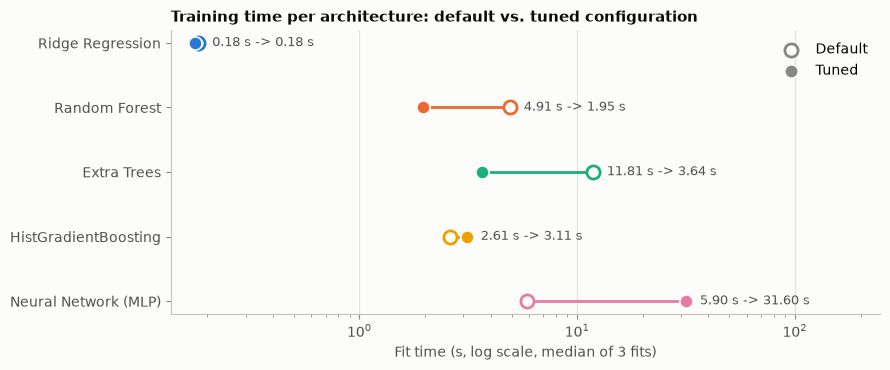

In [7]:
fig, ax = plt.subplots(figsize = (9, 3.8))

for i, name in enumerate(MODEL_NAMES):
    rows = headline_df[headline_df["Model"] == name].set_index("Config")
    ax.plot([rows.loc["Default", "Fit time (s)"], rows.loc["Tuned", "Fit time (s)"]], [i, i],
            color = COLORS[name], linewidth = 2, zorder = 2)
    ax.scatter(rows.loc["Default", "Fit time (s)"], i, s = 90, facecolor = "#fcfcfb",
               edgecolor = COLORS[name], linewidth = 2, zorder = 3)
    ax.scatter(rows.loc["Tuned", "Fit time (s)"], i, s = 90, facecolor = COLORS[name],
               edgecolor = "#fcfcfb", linewidth = 1.2, zorder = 4)
    slowest = rows["Fit time (s)"].max()
    ax.annotate(f"{rows.loc['Default', 'Fit time (s)']:.2f} s -> {rows.loc['Tuned', 'Fit time (s)']:.2f} s",
                (slowest, i), xytext = (10, 0), textcoords = "offset points",
                va = "center", color = "#52514e", fontsize = 9)

ax.scatter([], [], s = 90, facecolor = "#fcfcfb", edgecolor = MUTED, linewidth = 2, label = "Default")
ax.scatter([], [], s = 90, facecolor = MUTED, edgecolor = "#fcfcfb", label = "Tuned")
ax.set_xscale("log")
ax.set_xlim(right = ax.get_xlim()[1] * 6)
ax.set_yticks(range(len(MODEL_NAMES)), MODEL_NAMES)
ax.invert_yaxis()
ax.grid(axis = "y", visible = False)
ax.set_xlabel("Fit time (s, log scale, median of 3 fits)")
ax.set_title("Training time per architecture: default vs. tuned configuration")
ax.legend(loc = "upper right")
plt.tight_layout()
plt.show()

## 3. How hyperparameters affect training speed

Each sweep starts from the tuned configuration and changes **one** hyperparameter at a time, so the difference in fit time can be attributed to that parameter. The top row of each figure is fit time and the bottom row is validation RMSE for the same fits.

For HistGradientBoosting and the MLP, early stopping decides how many boosting iterations / epochs actually run, so that count is recorded as well (`Iterations`).

In [8]:
sweeps = {
    "Ridge Regression": {"alpha": [1e-3, 1.0, 659.871107205407, 1e4]},
    "Random Forest": {"n_estimators": [25, 50, 100, 200, 400],
                      "max_depth": [5, 10, 20, None],
                      "max_features": ["log2", "sqrt", 0.1, 0.3],
                      "n_jobs": [1, 2, 4, 6, 12]},
    "Extra Trees": {"n_estimators": [25, 50, 100, 200, 400],
                    "max_depth": [5, 10, 20, None],
                    "max_features": ["log2", "sqrt", 0.1, 0.3]},
    "HistGradientBoosting": {"max_iter": [50, 100, 200, 400],
                             "learning_rate": [0.01, 0.03, 0.1, 0.2],
                             "max_leaf_nodes": [7, 11, 31, 63]},
    "Neural Network (MLP)": {"hidden_layer_sizes": [(64,), (128, 64), (128, 64, 32), (256, 128)],
                             "batch_size": [32, 64, 128, 256],
                             "learning_rate_init": [1e-4, 1e-3, 1e-2]}}

sweep_rows = []
for name, param_grid in sweeps.items():
    for param, values in param_grid.items():
        for value in values:
            row = {"Model": name, "Parameter": param, "Value": str(value)}
            row.update(bench(make_model(name, **{param: value})))
            sweep_rows.append(row)
    print(f"Finished sweeps for {name}")

sweep_df = pd.DataFrame(sweep_rows)
sweep_df["Seconds per iteration"] = sweep_df["Fit time (s)"] / sweep_df["Iterations"]

Finished sweeps for Ridge Regression
Finished sweeps for Random Forest
Finished sweeps for Extra Trees
Finished sweeps for HistGradientBoosting
Finished sweeps for Neural Network (MLP)


In [9]:
def short_label(value):
    # Compact tick label for a hyperparameter value
    try:
        return f"{float(value):.3g}"
    except ValueError:
        return value.replace(" ", "")

def plot_sweeps(name):
    data = sweep_df[sweep_df["Model"] == name]
    params = list(sweeps[name])
    fig, axes = plt.subplots(2, len(params), figsize = (3.4 * len(params) + 0.6, 5.2),
                             sharex = "col", squeeze = False)

    for j, param in enumerate(params):
        rows = data[data["Parameter"] == param]
        xs = range(len(rows))
        axes[0, j].plot(xs, rows["Fit time (s)"], **series_style(name))
        axes[0, j].set_ylim(bottom = 0)
        axes[0, j].set_title(param)
        axes[1, j].plot(xs, rows["Val RMSE"], **series_style(name))
        axes[1, j].axhline(baseline_val_rmse, color = MUTED, linewidth = 1, linestyle = "--")
        axes[1, j].set_xticks(xs, [short_label(v) for v in rows["Value"]])

    axes[0, 0].set_ylabel("Fit time (s)")
    axes[1, 0].set_ylabel("Validation RMSE")
    axes[1, -1].annotate("mean baseline", (1, baseline_val_rmse), xycoords = ("axes fraction", "data"),
                         xytext = (-4, 4), textcoords = "offset points",
                         ha = "right", color = MUTED, fontsize = 8)
    fig.suptitle(f"{name}: one hyperparameter changed at a time (other settings = tuned)",
                 x = 0.01, ha = "left", fontsize = 12, fontweight = "bold", color = INK)
    plt.tight_layout()
    plt.show()

    columns = ["Parameter", "Value", "Fit time (s)", "Val RMSE", "Test RMSE"]
    if data["Iterations"].notna().any():
        columns += ["Iterations", "Seconds per iteration"]
    print(data[columns].to_string(index = False))

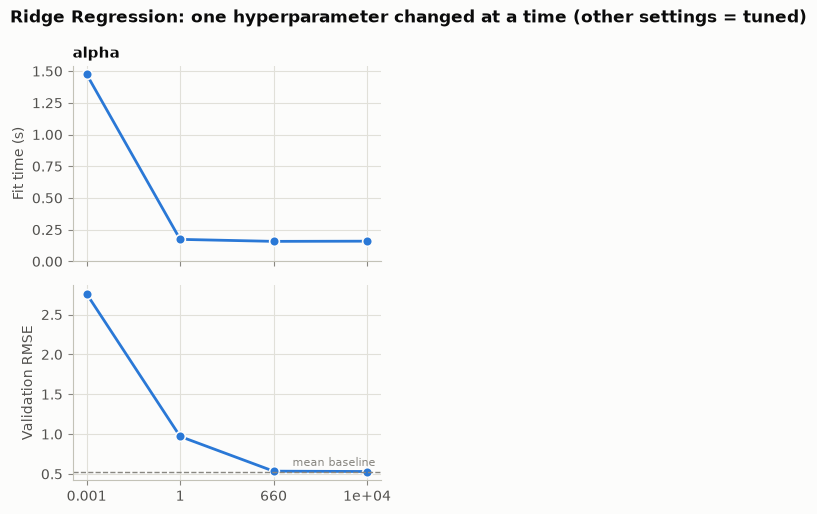

Parameter            Value  Fit time (s)  Val RMSE  Test RMSE
    alpha            0.001         1.475      2.76      2.814
    alpha              1.0        0.1734    0.9704      1.639
    alpha 659.871107205407        0.1576    0.5347       1.41
    alpha          10000.0        0.1592    0.5304      1.393


In [10]:
plot_sweeps("Ridge Regression")

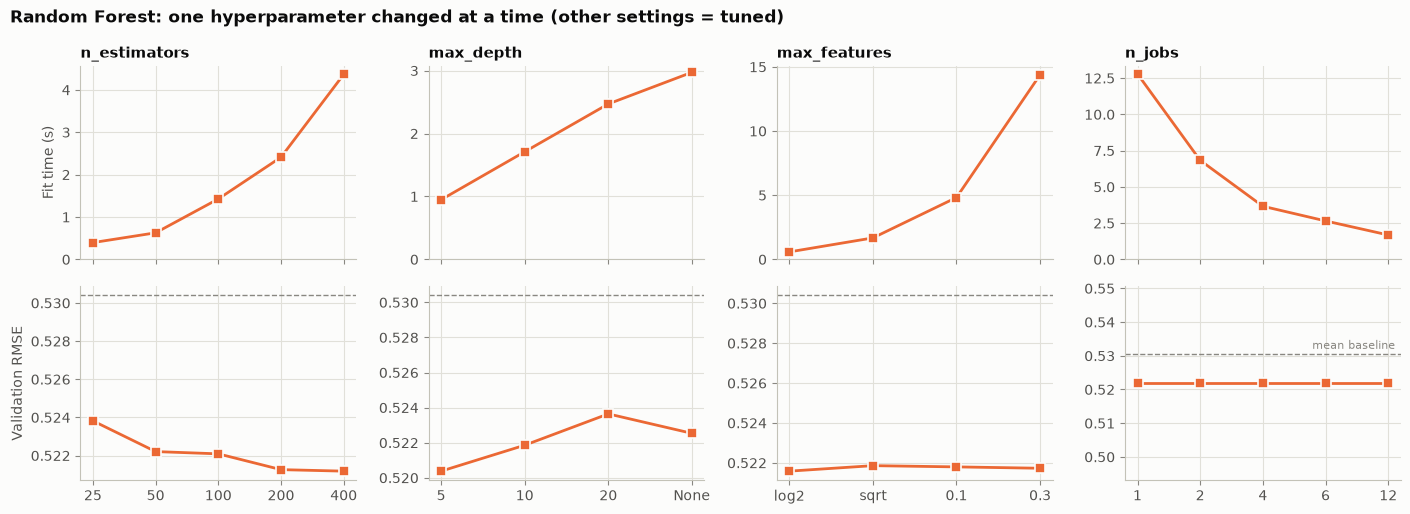

   Parameter Value  Fit time (s)  Val RMSE  Test RMSE
n_estimators    25        0.3962    0.5238      1.348
n_estimators    50        0.6272    0.5222      1.348
n_estimators   100         1.427    0.5221      1.348
n_estimators   200         2.411    0.5213      1.347
n_estimators   400         4.366    0.5212      1.347
   max_depth     5        0.9485    0.5204      1.343
   max_depth    10         1.711    0.5219      1.348
   max_depth    20          2.47    0.5236      1.351
   max_depth  None         2.973    0.5225      1.353
max_features  log2        0.5833    0.5216      1.346
max_features  sqrt         1.674    0.5219      1.348
max_features   0.1         4.822    0.5218       1.35
max_features   0.3         14.38    0.5217       1.35
      n_jobs     1         12.79    0.5219      1.348
      n_jobs     2         6.831    0.5219      1.348
      n_jobs     4         3.664    0.5219      1.348
      n_jobs     6         2.652    0.5219      1.348
      n_jobs    12         1

In [11]:
plot_sweeps("Random Forest")

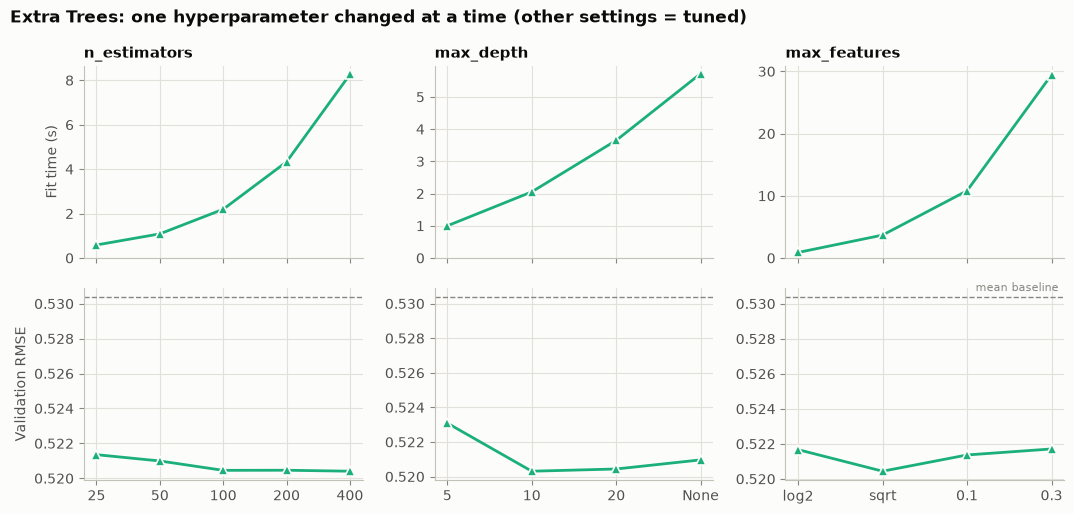

   Parameter Value  Fit time (s)  Val RMSE  Test RMSE
n_estimators    25        0.5867    0.5214      1.343
n_estimators    50         1.086     0.521      1.342
n_estimators   100         2.193    0.5205      1.342
n_estimators   200         4.328    0.5205      1.342
n_estimators   400          8.26    0.5204      1.342
   max_depth     5        0.9984    0.5231      1.366
   max_depth    10         2.052    0.5203      1.348
   max_depth    20         3.651    0.5204      1.342
   max_depth  None         5.725     0.521      1.343
max_features  log2         0.889    0.5217      1.357
max_features  sqrt         3.682    0.5204      1.342
max_features   0.1         10.81    0.5214      1.343
max_features   0.3         29.44    0.5217      1.343


In [12]:
plot_sweeps("Extra Trees")

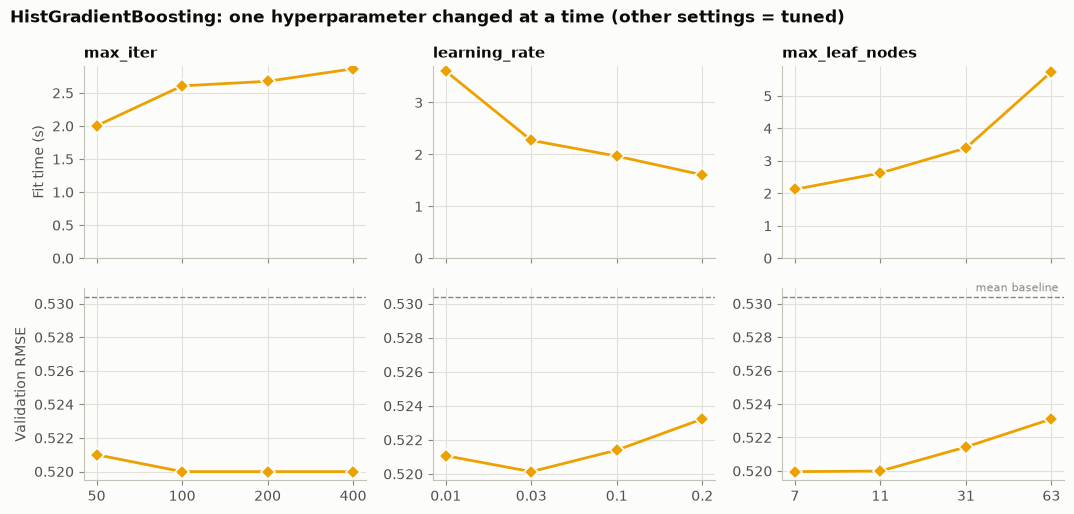

     Parameter Value  Fit time (s)  Val RMSE  Test RMSE  Iterations  Seconds per iteration
      max_iter    50         2.004     0.521      1.352          50                0.04008
      max_iter   100         2.607      0.52      1.346          95                0.02744
      max_iter   200         2.677      0.52      1.346          95                0.02818
      max_iter   400         2.866      0.52      1.346          95                0.03016
 learning_rate  0.01         3.604    0.5211      1.352         152                0.02371
 learning_rate  0.03         2.271    0.5201      1.348          71                0.03199
 learning_rate   0.1         1.967    0.5214      1.345          52                0.03782
 learning_rate   0.2         1.606    0.5232      1.344          25                0.06422
max_leaf_nodes     7         2.121      0.52      1.347          87                0.02438
max_leaf_nodes    11         2.624      0.52      1.346          95                0.02762

In [13]:
plot_sweeps("HistGradientBoosting")

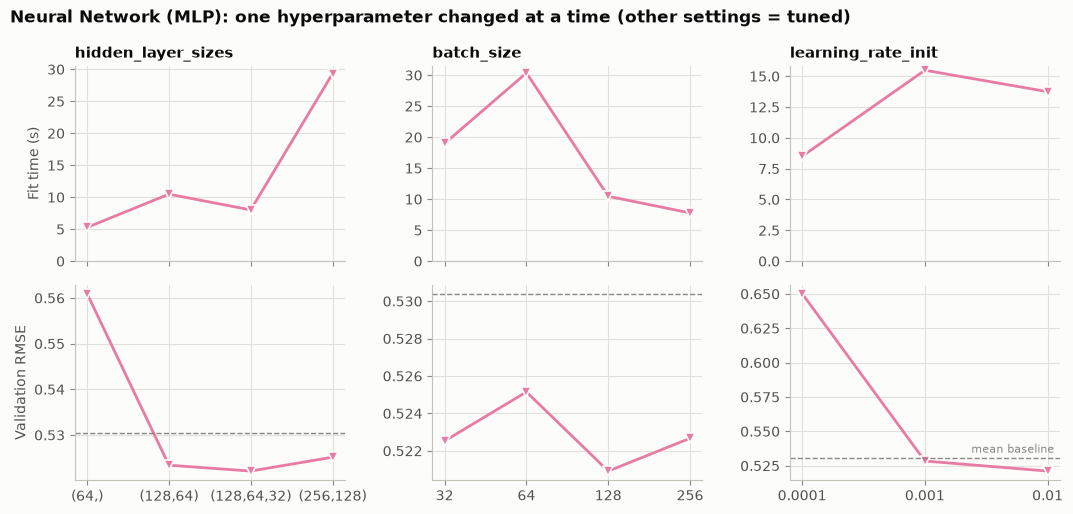

         Parameter         Value  Fit time (s)  Val RMSE  Test RMSE  Iterations  Seconds per iteration
hidden_layer_sizes         (64,)         5.271     0.561      1.425          44                 0.1198
hidden_layer_sizes     (128, 64)         10.47    0.5234      1.364          49                 0.2137
hidden_layer_sizes (128, 64, 32)          8.01    0.5221      1.365          34                 0.2356
hidden_layer_sizes    (256, 128)         29.32    0.5251      1.336          77                 0.3808
        batch_size            32         18.99    0.5225      1.351          28                 0.6781
        batch_size            64         30.35    0.5251      1.336          77                 0.3942
        batch_size           128         10.46    0.5209       1.35          44                 0.2377
        batch_size           256         7.773    0.5227      1.355          48                 0.1619
learning_rate_init        0.0001         8.507    0.6502      1.546      

In [14]:
plot_sweeps("Neural Network (MLP)")

### Training-set size

How fit time grows with the number of training recordings (tuned configurations). The scaling exponent is the slope of log(time) against log(n): 1.0 means time doubles when the data doubles.

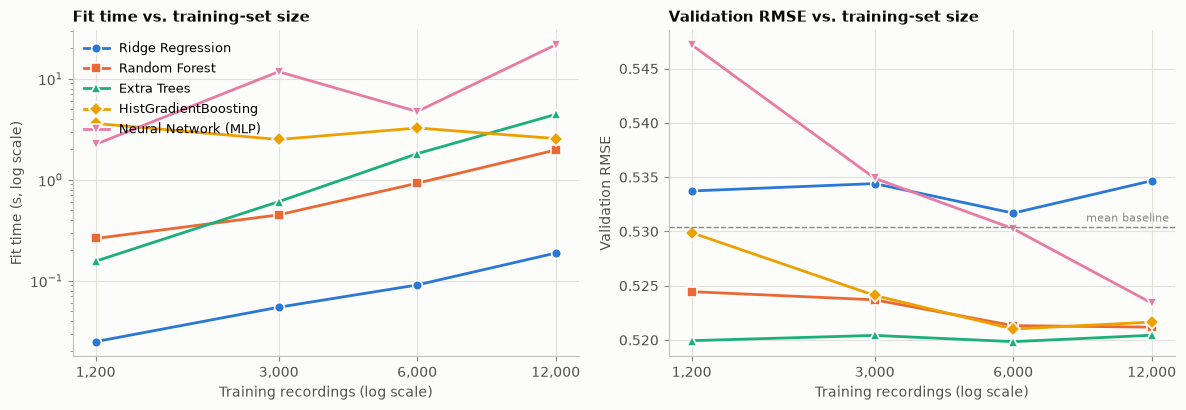

Fit time (s) by number of training recordings:
Recordings              1200    3000   6000  12000  Scaling exponent
Model                                                               
Ridge Regression     0.02497 0.05471 0.0909 0.1881            0.8624
Random Forest         0.2623  0.4493 0.9242   1.97            0.8814
Extra Trees           0.1562  0.6071  1.811  4.432             1.466
HistGradientBoosting    3.61   2.504  3.255  2.558           -0.1077
Neural Network (MLP)   2.241   11.75  4.735  21.68            0.7939


In [15]:
rng = np.random.default_rng(42)
shuffled = rng.permutation(len(X_fit))
fractions = [0.1, 0.25, 0.5, 1.0]

size_rows = []
for frac in fractions:
    subset = shuffled[:int(frac * len(X_fit))]
    for name in MODEL_NAMES:
        row = {"Model": name, "Fraction": frac, "Recordings": len(subset)}
        row.update(bench(make_model(name), Xf = X_fit[subset], yf = y_fit[subset], repeats = 3))
        size_rows.append(row)

size_df = pd.DataFrame(size_rows)

fig, axes = plt.subplots(1, 2, figsize = (12, 4.2))
exponents = {}
for name in MODEL_NAMES:
    rows = size_df[size_df["Model"] == name]
    axes[0].plot(rows["Recordings"], rows["Fit time (s)"], label = name, **series_style(name))
    axes[1].plot(rows["Recordings"], rows["Val RMSE"], label = name, **series_style(name))
    exponents[name] = np.polyfit(np.log(rows["Recordings"]), np.log(rows["Fit time (s)"]), 1)[0]

axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("Training recordings (log scale)")
axes[0].set_ylabel("Fit time (s, log scale)")
axes[0].set_title("Fit time vs. training-set size")
axes[0].legend(fontsize = 9)
axes[1].axhline(baseline_val_rmse, color = MUTED, linewidth = 1, linestyle = "--")
axes[1].annotate("mean baseline", (1, baseline_val_rmse), xycoords = ("axes fraction", "data"),
                 xytext = (-4, 4), textcoords = "offset points", ha = "right", color = MUTED, fontsize = 8)
axes[1].set_xscale("log")
for ax in axes:
    ax.set_xticks(sorted(size_df["Recordings"].unique()))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.xaxis.set_minor_locator(plt.NullLocator())
axes[1].set_xlabel("Training recordings (log scale)")
axes[1].set_ylabel("Validation RMSE")
axes[1].set_title("Validation RMSE vs. training-set size")
plt.tight_layout()
plt.show()

size_table = size_df.pivot(index = "Model", columns = "Recordings", values = "Fit time (s)").loc[MODEL_NAMES]
size_table["Scaling exponent"] = pd.Series(exponents)
print("Fit time (s) by number of training recordings:")
print(size_table.to_string())

### Input window length

The models see the first 3 s (300 samples) of each trace. A shorter window means fewer features (3 x samples), which is cheaper to train on and, in deployment, means less waiting for data after the trace starts.

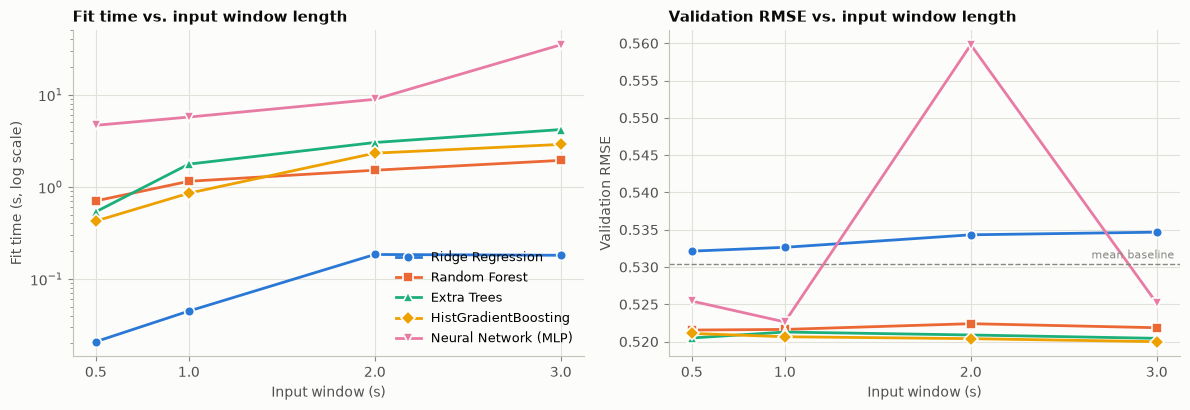

Fit time (s):
Window (s)               0.5     1      2      3  
Model                                             
Ridge Regression     0.02088 0.04483 0.1845 0.1808
Random Forest         0.7034   1.148  1.514  1.936
Extra Trees           0.5358   1.763  3.025  4.182
HistGradientBoosting  0.4257  0.8526  2.319  2.885
Neural Network (MLP)   4.653   5.714  8.904  34.77

Validation RMSE:
Window (s)              0.5    1      2      3  
Model                                           
Ridge Regression     0.5321 0.5326 0.5343 0.5347
Random Forest        0.5215 0.5216 0.5224 0.5219
Extra Trees          0.5205 0.5213 0.5209 0.5204
HistGradientBoosting 0.5211 0.5206 0.5204   0.52
Neural Network (MLP) 0.5254 0.5226 0.5598 0.5251


In [16]:
windows = [50, 100, 200, 300]  # samples at 100 Hz -> 0.5, 1, 2, 3 s

window_rows = []
for w in windows:
    X_w = flatten(X, w)
    for name in MODEL_NAMES:
        row = {"Model": name, "Window (s)": w / 100, "Features": X_w.shape[1]}
        row.update(bench(make_model(name), Xf = X_w[fit_idx], Xv = X_w[val_idx], Xt = X_w[test_idx], repeats = 3))
        window_rows.append(row)
    del X_w

window_df = pd.DataFrame(window_rows)

fig, axes = plt.subplots(1, 2, figsize = (12, 4.2))
for name in MODEL_NAMES:
    rows = window_df[window_df["Model"] == name]
    axes[0].plot(rows["Window (s)"], rows["Fit time (s)"], label = name, **series_style(name))
    axes[1].plot(rows["Window (s)"], rows["Val RMSE"], label = name, **series_style(name))

axes[0].set_yscale("log")
axes[0].set_xlabel("Input window (s)")
axes[0].set_ylabel("Fit time (s, log scale)")
axes[0].set_title("Fit time vs. input window length")
axes[0].legend(fontsize = 9)
axes[1].axhline(baseline_val_rmse, color = MUTED, linewidth = 1, linestyle = "--")
axes[1].annotate("mean baseline", (1, baseline_val_rmse), xycoords = ("axes fraction", "data"),
                 xytext = (-4, 4), textcoords = "offset points", ha = "right", color = MUTED, fontsize = 8)
axes[1].set_xlabel("Input window (s)")
axes[1].set_ylabel("Validation RMSE")
axes[1].set_title("Validation RMSE vs. input window length")
for ax in axes:
    ax.set_xticks([w / 100 for w in windows])
plt.tight_layout()
plt.show()

print("Fit time (s):")
print(window_df.pivot(index = "Model", columns = "Window (s)", values = "Fit time (s)").loc[MODEL_NAMES].to_string())
print("\nValidation RMSE:")
print(window_df.pivot(index = "Model", columns = "Window (s)", values = "Val RMSE").loc[MODEL_NAMES].to_string())

## 4. Time vs. accuracy trade-offs

Every configuration timed above on the full 900-feature fit set (default, tuned, and each hyperparameter sweep point) is one marker: fit time against error. Lower-left is better. The two panels use the same fits scored on different data:

- **Validation** - unseen events with M < 2, the same magnitude range the models were trained on.
- **Test** - events with M >= 2, larger than anything in training.

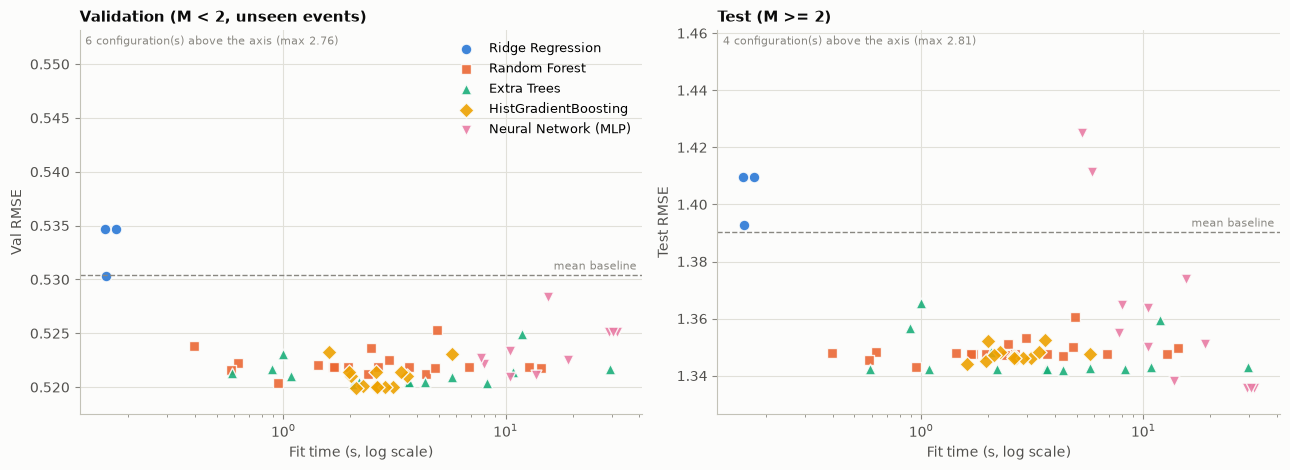

In [17]:
headline_cfg = headline_df.assign(Configuration = headline_df["Config"])
sweep_cfg = sweep_df.assign(Configuration = sweep_df["Parameter"] + "=" + sweep_df["Value"])
keep_cols = ["Model", "Configuration", "Fit time (s)", "Predict (ms / 1000 traces)", "Val RMSE", "Test RMSE"]
all_cfg = pd.concat([headline_cfg[keep_cols], sweep_cfg[keep_cols]], ignore_index = True)

fig, axes = plt.subplots(1, 2, figsize = (13, 4.8), sharex = True)
panels = [("Val RMSE", baseline_val_rmse, "Validation (M < 2, unseen events)"),
          ("Test RMSE", baseline_test_rmse, "Test (M >= 2)")]

for ax, (metric, base, title) in zip(axes, panels):
    for name in MODEL_NAMES:
        rows = all_cfg[all_cfg["Model"] == name]
        ax.scatter(rows["Fit time (s)"], rows[metric], s = 60, color = COLORS[name],
                   marker = MARKERS[name], edgecolor = "#fcfcfb", linewidth = 1,
                   alpha = 0.9, label = name)
    ax.axhline(base, color = MUTED, linewidth = 1, linestyle = "--")
    ax.annotate("mean baseline", (1, base), xycoords = ("axes fraction", "data"),
                xytext = (-4, 4), textcoords = "offset points", ha = "right", color = MUTED, fontsize = 8)
    ax.set_xscale("log")
    ax.set_xlabel("Fit time (s, log scale)")
    ax.set_ylabel(metric)
    ax.set_title(title)

# Keep the bulk of the points readable if one configuration is far worse than the rest
for ax, (metric, base, _) in zip(axes, panels):
    upper = max(base, all_cfg[metric].quantile(0.9)) * 1.03
    clipped = all_cfg[all_cfg[metric] > upper]
    lower = all_cfg[metric].min()
    pad = 0.08 * (upper - lower)
    ax.set_ylim(lower - pad, upper + pad)
    if len(clipped):
        ax.annotate(f"{len(clipped)} configuration(s) above the axis (max {clipped[metric].max():.2f})",
                    (0, 1), xycoords = "axes fraction", xytext = (4, -4), textcoords = "offset points",
                    ha = "left", va = "top", color = MUTED, fontsize = 8)

axes[0].legend(fontsize = 9, loc = "upper right")
plt.tight_layout()
plt.show()

In [18]:
def pareto_front(frame, metric):
    # Configurations where no other configuration is both faster to fit and more accurate
    ordered = frame.sort_values(["Fit time (s)", metric])
    best, selected = np.inf, []
    for idx, value in zip(ordered.index, ordered[metric]):
        if value < best:
            selected.append(idx)
            best = value
    return frame.loc[selected]

print("Fastest-for-its-accuracy configurations (validation RMSE):")
print(pareto_front(all_cfg, "Val RMSE")[["Model", "Configuration", "Fit time (s)", "Val RMSE", "Test RMSE"]].to_string(index = False))

print("\nFastest-for-its-accuracy configurations (test RMSE):")
print(pareto_front(all_cfg, "Test RMSE")[["Model", "Configuration", "Fit time (s)", "Val RMSE", "Test RMSE"]].to_string(index = False))

spread = all_cfg.groupby("Model").agg(**{"Configurations": ("Fit time (s)", "size"),
                                         "Fastest fit (s)": ("Fit time (s)", "min"),
                                         "Slowest fit (s)": ("Fit time (s)", "max"),
                                         "Best Val RMSE": ("Val RMSE", "min"),
                                         "Worst Val RMSE": ("Val RMSE", "max"),
                                         "Best Test RMSE": ("Test RMSE", "min"),
                                         "Worst Test RMSE": ("Test RMSE", "max")}).loc[MODEL_NAMES]
print("\nRange across all configurations of each model:")
print(spread.to_string())
print(f"\nMean baseline - Val RMSE: {baseline_val_rmse:.4f}, Test RMSE: {baseline_test_rmse:.4f}")

Fastest-for-its-accuracy configurations (validation RMSE):
               Model          Configuration  Fit time (s)  Val RMSE  Test RMSE
    Ridge Regression alpha=659.871107205407        0.1576    0.5347       1.41
    Ridge Regression          alpha=10000.0        0.1592    0.5304      1.393
       Random Forest        n_estimators=25        0.3962    0.5238      1.348
       Random Forest      max_features=log2        0.5833    0.5216      1.346
         Extra Trees        n_estimators=25        0.5867    0.5214      1.343
       Random Forest            max_depth=5        0.9485    0.5204      1.343
         Extra Trees           max_depth=10         2.052    0.5203      1.348
HistGradientBoosting       max_leaf_nodes=7         2.121      0.52      1.347

Fastest-for-its-accuracy configurations (test RMSE):
               Model                 Configuration  Fit time (s)  Val RMSE  Test RMSE
    Ridge Regression        alpha=659.871107205407        0.1576    0.5347       1.41
    

## 5. Deployment time requirements

For deployment each tuned model is refit on **all** M < 2 training recordings (the fit and validation parts together). Then, per model:

- **Batch throughput** - predicting the whole test set in one call (reprocessing a catalog).
- **Single-trace latency** - one `predict` call per trace, 200 traces (a real-time stream where picks arrive one at a time). Median and 95th percentile.
- **Model size and load time** - the model saved with `joblib`, as it would be shipped.

The forests are measured twice for single traces: with the `n_jobs = -1` they were trained with, and with `n_jobs = 1` set after training, because starting 12 worker threads for one trace can cost more than the prediction itself.

In [19]:
def single_trace_latency(model, n_calls = 200):
    # Milliseconds per predict call when traces arrive one at a time
    model.predict(X_test[:1])  # warm-up
    times = []
    for i in range(n_calls):
        row = X_test[i:i + 1]
        start = time.perf_counter()
        model.predict(row)
        times.append(1000 * (time.perf_counter() - start))
    return float(np.median(times)), float(np.percentile(times, 95))

deployed = {}
deploy_rows = []

with tempfile.TemporaryDirectory() as tmp_dir:
    for name in MODEL_NAMES:
        model = make_model(name)
        start = time.perf_counter()
        model.fit(X_train, y_train)
        fit_seconds = time.perf_counter() - start
        deployed[name] = model

        batch_times = []
        for _ in range(3):
            start = time.perf_counter()
            test_pred = model.predict(X_test)
            batch_times.append(time.perf_counter() - start)
        batch_seconds = float(np.median(batch_times))

        path = os.path.join(tmp_dir, "model.joblib")
        joblib.dump(model, path)
        size_mb = os.path.getsize(path) / 1e6
        start = time.perf_counter()
        joblib.load(path)
        load_seconds = time.perf_counter() - start

        variants = [(name, None)]
        if name in ("Random Forest", "Extra Trees"):
            variants = [(f"{name} (n_jobs=-1)", -1), (f"{name} (n_jobs=1)", 1)]

        for label, n_jobs in variants:
            if n_jobs is not None:
                model.set_params(n_jobs = n_jobs)
            median_ms, p95_ms = single_trace_latency(model)
            deploy_rows.append({"Model": label,
                                "Full fit (s)": fit_seconds,
                                "Batch (traces/s)": len(X_test) / batch_seconds,
                                "Single trace median (ms)": median_ms,
                                "Single trace p95 (ms)": p95_ms,
                                "Size (MB)": size_mb,
                                "Load (s)": load_seconds,
                                "Test RMSE": rmse(y_test, test_pred)})
        if name in ("Random Forest", "Extra Trees"):
            model.set_params(n_jobs = -1)

deploy_df = pd.DataFrame(deploy_rows)
print(deploy_df.to_string(index = False))

                    Model  Full fit (s)  Batch (traces/s)  Single trace median (ms)  Single trace p95 (ms)  Size (MB)  Load (s)  Test RMSE
         Ridge Regression        0.3481         6.138e+05                    0.2381                 0.3724    0.02624 0.0006882      1.407
Random Forest (n_jobs=-1)           2.5         5.177e+04                     38.72                  49.02      4.714   0.02022       1.34
 Random Forest (n_jobs=1)           2.5         5.177e+04                     8.305                  11.83      4.714   0.02022       1.34
  Extra Trees (n_jobs=-1)          5.63         4.504e+04                     49.46                  52.81      11.19    0.0281      1.338
   Extra Trees (n_jobs=1)          5.63         4.504e+04                      9.91                  12.85      11.19    0.0281      1.338
     HistGradientBoosting         2.428         3.516e+05                    0.6855                  1.533       1.11   0.02352      1.345
     Neural Network (MLP)  

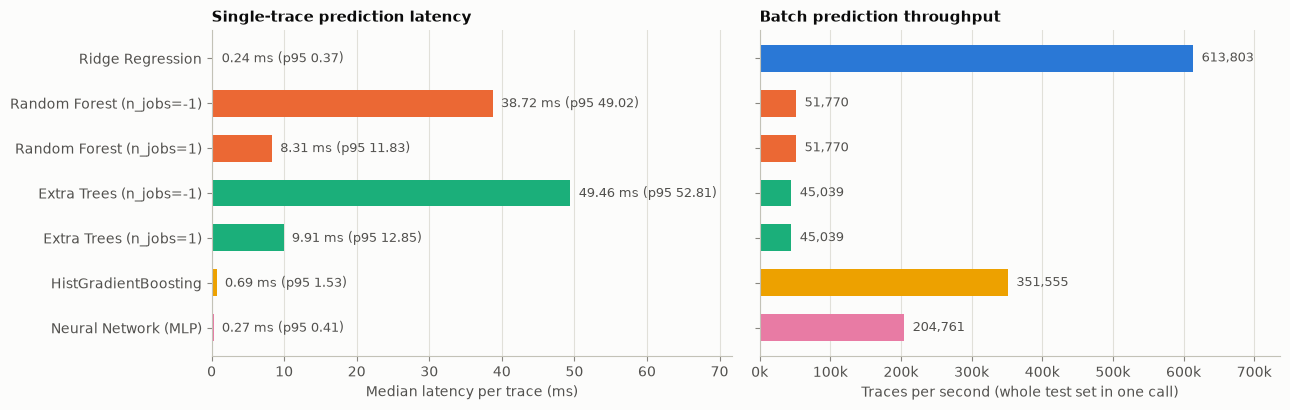

In [20]:
fig, axes = plt.subplots(1, 2, figsize = (13, 4.2))
labels = deploy_df["Model"].tolist()
bar_colors = [COLORS[next(m for m in MODEL_NAMES if label.startswith(m))] for label in labels]
positions = range(len(labels))

axes[0].barh(positions, deploy_df["Single trace median (ms)"], color = bar_colors, height = 0.6)
for i, (median_ms, p95_ms) in enumerate(zip(deploy_df["Single trace median (ms)"], deploy_df["Single trace p95 (ms)"])):
    axes[0].annotate(f"{median_ms:.2f} ms (p95 {p95_ms:.2f})", (median_ms, i), xytext = (6, 0),
                     textcoords = "offset points", va = "center", color = "#52514e", fontsize = 9)
axes[0].set_xlim(right = deploy_df["Single trace median (ms)"].max() * 1.45)
axes[0].set_xlabel("Median latency per trace (ms)")
axes[0].set_title("Single-trace prediction latency")

axes[1].barh(positions, deploy_df["Batch (traces/s)"], color = bar_colors, height = 0.6)
for i, rate in enumerate(deploy_df["Batch (traces/s)"]):
    axes[1].annotate(f"{rate:,.0f}", (rate, i), xytext = (6, 0), textcoords = "offset points",
                     va = "center", color = "#52514e", fontsize = 9)
axes[1].set_xlim(right = deploy_df["Batch (traces/s)"].max() * 1.2)
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:,.0f}k"))
axes[1].set_xlabel("Traces per second (whole test set in one call)")
axes[1].set_title("Batch prediction throughput")

for ax in axes:
    ax.set_yticks(positions, labels)
    ax.invert_yaxis()
    ax.grid(axis = "y", visible = False)
axes[1].set_yticklabels([])
plt.tight_layout()
plt.show()

### Expected time in real-world scenarios

These combine the measurements above into end-to-end estimates on this machine:

- **Real-time, one trace** - the model cannot run until the 3 s input window has been recorded, so the response time after a trace starts is the 3 s window plus the single-trace latency. (The HDF5 read time is shown for reference; a live system would receive samples from a stream instead.)
- **Catalog reprocessing** - read every trace from HDF5 and predict in batch, for this dataset (18,640 traces) and for a hypothetical archive of 1,000,000 traces. Reading is single-threaded here.
- **Retraining** - one full fit, and a full re-tune. The re-tune times are the wall-clock times recorded in the output of `AutoML_Hyperparameter_Tuning.ipynb` for its randomized search (12 candidates x 3 folds = 36 fits per model, 6 parallel workers); they are copied in below, not re-measured here.

In [21]:
WINDOW_SECONDS = N_SAMPLES / 100
N_CATALOG = len(X)
N_ARCHIVE = 1_000_000

# Wall-clock seconds of the randomized search, copied from the AutoML notebook output
AUTOML_TUNING_SECONDS = {"Ridge Regression": 13.6, "Random Forest": 248.0, "Extra Trees": 368.3,
                         "HistGradientBoosting": 106.3, "Neural Network (MLP)": 242.3}

# Use the faster single-trace variant for the forests
best_single = {}
for name in MODEL_NAMES:
    rows = deploy_df[deploy_df["Model"].str.startswith(name)]
    best_single[name] = rows.loc[rows["Single trace median (ms)"].idxmin()]

scenario_rows = []
for name in MODEL_NAMES:
    row = best_single[name]
    predict_s_per_trace = 1 / row["Batch (traces/s)"]
    read_s_per_trace = read_ms_per_trace / 1000
    scenario_rows.append({
        "Model": name,
        "Real-time: window + inference (s)": WINDOW_SECONDS + row["Single trace median (ms)"] / 1000,
        "Inference share of real-time (%)": 100 * (row["Single trace median (ms)"] / 1000) / (WINDOW_SECONDS + row["Single trace median (ms)"] / 1000),
        "Single-trace capacity (traces/s)": 1000 / row["Single trace median (ms)"],
        f"Catalog {N_CATALOG:,}: read + predict (s)": N_CATALOG * (read_s_per_trace + predict_s_per_trace),
        f"Archive {N_ARCHIVE:,}: read + predict (min)": N_ARCHIVE * (read_s_per_trace + predict_s_per_trace) / 60,
        "Predict share of batch time (%)": 100 * predict_s_per_trace / (read_s_per_trace + predict_s_per_trace),
        "Retrain: one full fit (s)": row["Full fit (s)"],
        "Re-tune: AutoML search (min)": AUTOML_TUNING_SECONDS[name] / 60})

scenario_df = pd.DataFrame(scenario_rows).set_index("Model")
print(f"HDF5 read: {read_ms_per_trace:.2f} ms per trace\n")
print(scenario_df.T.to_string())

HDF5 read: 2.83 ms per trace

Model                                    Ridge Regression  Random Forest  Extra Trees  HistGradientBoosting  Neural Network (MLP)
Real-time: window + inference (s)                       3          3.008         3.01                 3.001                     3
Inference share of real-time (%)                 0.007934         0.2761       0.3292               0.02285              0.008951
Single-trace capacity (traces/s)                     4201          120.4        100.9                  1459                  3724
Catalog 18,640: read + predict (s)                  52.74          53.07        53.12                 52.76                  52.8
Archive 1,000,000: read + predict (min)             47.16          47.45         47.5                 47.18                 47.21
Predict share of batch time (%)                   0.05758         0.6784       0.7791                0.1005                0.1724
Retrain: one full fit (s)                          0.3481   

## 6. Timing the final model (feature-based HistGradientBoosting)

`Model_Training_Assessment.ipynb` replaced the raw 300-sample window with 23 features measured around the P and S picks (amplitudes, coda duration, band powers, S-P time, channel type) and selected a tuned `HistGradientBoostingRegressor` (test RMSE 0.415 vs. 0.716 for the mean baseline). This section times that pipeline end to end:

- **Feature extraction** - reading one full trace from HDF5 and computing its features. The feature function is copied unchanged from `Model_Training_Assessment.ipynb`, and timed on a random sample of 500 traces.
- **Training and prediction** - the final hyperparameters, fitted on the cached feature table (`data/ai_ready/waveform_features.parquet`, written by that notebook) using the same development period (first 85% of events in time).
- **Waiting for data** - the features need signal well after the P arrival, which sets the real-time response time.

In [22]:
FS = 100
BANDS = [(0.5, 1), (1, 2), (2, 4), (4, 8), (8, 16), (16, 32)]

def trace_features(x, p, s):
    # Copied from Model_Training_Assessment.ipynb: features for one (3, 15001) trace from the vertical channel and the P/S picks
    z_raw = np.asarray(x[2], dtype=np.float64)
    n = z_raw.size
    noise_sl = slice(max(0, p - 3000), p - 100)
    z = z_raw - z_raw[noise_sl].mean()
    eps = 1e-3
    noise_rms = z[noise_sl].std() + eps
    p_end = max(min(s, p + 500), p + 50)
    p_win, s_win, sig = z[p:p_end], z[s:min(s + 1000, n)], z[p:min(p + 6000, n)]
    f = {"log_noise_rms": np.log10(noise_rms),
         "log_p_peak": np.log10(np.abs(p_win).max() + eps),
         "log_p_rms": np.log10(p_win.std() + eps),
         "log_s_peak": np.log10(np.abs(s_win).max() + eps),
         "log_s_rms": np.log10(s_win.std() + eps),
         "log_peak": np.log10(np.abs(sig).max() + eps)}
    f["log_snr"] = f["log_peak"] - f["log_noise_rms"]
    w = 200
    c = np.concatenate([[0.0], np.cumsum(z[p:] ** 2)])
    env = np.sqrt((c[w:] - c[:-w]) / w)
    i_pk = int(env.argmax())
    for k in (2, 4):
        below = np.nonzero(env[i_pk:] < k * noise_rms)[0]
        dur = (i_pk + below[0]) if below.size else env.size
        f[f"log_coda_dur_{k}x"] = np.log10((dur + 1) / FS)
    f["coda_censored"] = float(below.size == 0)
    seg = z[p:min(p + 3000, n)]
    spec = np.abs(np.fft.rfft(seg * np.hanning(seg.size))) ** 2
    fr = np.fft.rfftfreq(seg.size, 1 / FS)
    for lo, hi in BANDS:
        f[f"log_pow_{lo}_{hi}Hz"] = np.log10(spec[(fr >= lo) & (fr < hi)].mean() + eps)
    m = (fr >= 0.5) & (fr < 40)
    f["spec_centroid_hz"] = float((fr[m] * spec[m]).sum() / (spec[m].sum() + eps))
    a = np.abs(z_raw[p:min(p + 6000, n)] - np.median(z_raw))
    f["clip_frac"] = float((a >= 0.98 * a.max()).mean()) if a.max() > 0 else 0.0
    f["sp_time_s"] = (s - p) / FS
    f["log_sp_time"] = np.log10((s - p) / FS)
    return f

# Time reading + feature extraction on 500 random traces (one full 3 x 15001 trace each)
sample_rows = matched_df.sample(500, random_state = 42).sort_values(["bucket", "tindex"])
read_times, feat_times = [], []
with h5py.File(raw_wave_path, "r") as hf:
    grp = hf["data"]
    for _, r in sample_rows.iterrows():
        b_val = str(r["bucket"]).strip()
        b_key = b_val if b_val.startswith("bucket") else f"bucket{b_val}"
        start = time.perf_counter()
        trace = grp[b_key][int(r["tindex"])]
        read_times.append(time.perf_counter() - start)
        start = time.perf_counter()
        trace_features(trace, int(r["trace_P_arrival_sample"]), int(r["trace_S_arrival_sample"]))
        feat_times.append(time.perf_counter() - start)

read_full_ms = 1000 * np.median(read_times)
feat_ms = 1000 * np.median(feat_times)
print(f"Read one full trace from HDF5: median {read_full_ms:.2f} ms (p95 {1000 * np.percentile(read_times, 95):.2f} ms)")
print(f"Feature extraction:            median {feat_ms:.2f} ms (p95 {1000 * np.percentile(feat_times, 95):.2f} ms)")
print(f"Whole dataset ({len(matched_df):,} traces), single process: ~{len(matched_df) * (read_full_ms + feat_ms) / 1000 / 60:.1f} min")

Read one full trace from HDF5: median 1.94 ms (p95 3.86 ms)
Feature extraction:            median 0.54 ms (p95 0.89 ms)
Whole dataset (18,640 traces), single process: ~0.8 min


In [23]:
# Train and predict with the final hyperparameters on the cached feature table
feature_cache = os.path.join(repo_root, "data", "ai_ready", "waveform_features.parquet")
feats = pd.read_parquet(feature_cache)
assert (feats.pop("trace_name").to_numpy() == df["trace_name"].to_numpy()).all()
for ch in ["EH", "BH", "HH"]:
    feats[f"chan_{ch}"] = (df["station_channel_code"] == ch).astype(float)

# Same development / test split as Model_Training_Assessment.ipynb: last 15% of events in time are the test period
origin = pd.to_datetime(df["source_origin_time"])
event_time = origin.groupby(df["event_id"]).first().sort_values()
test_events = event_time.index[-int(round(0.15 * len(event_time))):]
is_test = df["event_id"].isin(test_events).to_numpy()
X_feat_dev, y_feat_dev = feats.loc[~is_test].to_numpy(), df.loc[~is_test, "preferred_source_magnitude"].to_numpy()
X_feat_test, y_feat_test = feats.loc[is_test].to_numpy(), df.loc[is_test, "preferred_source_magnitude"].to_numpy()

final_params = {"l2_regularization": 0.12563152773938666, "learning_rate": 0.05022164887854354,
                "max_iter": 575, "max_leaf_nodes": 23, "min_samples_leaf": 24,
                "early_stopping": False, "random_state": 42}

fit_times = []
for _ in range(3):
    final_model = HistGradientBoostingRegressor(**final_params)
    start = time.perf_counter()
    final_model.fit(X_feat_dev, y_feat_dev)
    fit_times.append(time.perf_counter() - start)
final_fit_s = float(np.median(fit_times))

start = time.perf_counter()
test_pred = final_model.predict(X_feat_test)
final_batch_rate = len(X_feat_test) / (time.perf_counter() - start)

final_model.predict(X_feat_test[:1])
single = []
for i in range(200):
    start = time.perf_counter()
    final_model.predict(X_feat_test[i:i + 1])
    single.append(1000 * (time.perf_counter() - start))
final_single_ms = float(np.median(single))

with tempfile.TemporaryDirectory() as tmp_dir:
    path = os.path.join(tmp_dir, "final.joblib")
    joblib.dump(final_model, path)
    final_size_mb = os.path.getsize(path) / 1e6

print(f"Features: {X_feat_dev.shape[1]} | development recordings: {len(X_feat_dev):,} | test recordings: {len(X_feat_test):,}")
print(f"Fit time (median of 3): {final_fit_s:.2f} s")
print(f"Single-recording prediction: median {final_single_ms:.2f} ms (p95 {np.percentile(single, 95):.2f} ms)")
print(f"Batch prediction: {final_batch_rate:,.0f} recordings/s | saved model: {final_size_mb:.2f} MB")
print(f"Test RMSE: {rmse(y_feat_test, test_pred):.3f} (should match 0.415 in Model_Training_Assessment.ipynb)")

Features: 23 | development recordings: 15,232 | test recordings: 3,408
Fit time (median of 3): 1.19 s
Single-recording prediction: median 6.02 ms (p95 9.39 ms)
Batch prediction: 112,958 recordings/s | saved model: 1.60 MB
Test RMSE: 0.415 (should match 0.415 in Model_Training_Assessment.ipynb)


Seconds of signal needed after the P arrival (limited by the end of the trace):
min   49.4
50%     60
90%   75.1
99%   93.4
max   97.4

For comparison: Sections 2-5 used a 3 s window; S-P time alone is median 5.2 s


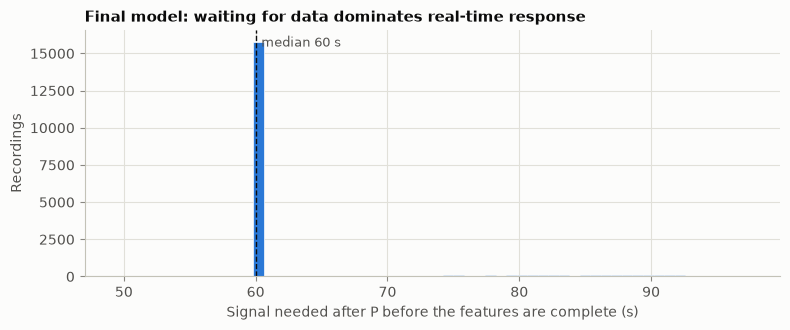


Final-model deployment summary (single process):
Wait for data after P, median (s)                       60
Feature extraction per trace (ms)                     0.54
Prediction per trace (ms)                             6.02
Full-trace HDF5 read (ms)                             1.94
Catalog of 18,640: read + features + predict (min)    0.77
Archive of 1,000,000: read + features + predict (h)   0.69
Retrain on all development data (s)                   1.19


In [24]:
# How much signal after the P arrival the features need before a prediction can be made.
# Fixed windows reach 60 s after P (peak amplitude, clipping) and 10 s after S (S window);
# the coda-duration features need the signal until the envelope falls below 2x the noise level.
sp_s = (df["trace_S_arrival_sample"] - df["trace_P_arrival_sample"]).to_numpy() / FS
coda_s = 10 ** feats["log_coda_dur_2x"].to_numpy()
avail_s = (15001 - df["trace_P_arrival_sample"].to_numpy()) / FS
need_s = np.minimum(np.maximum.reduce([np.full(len(df), 60.0), sp_s + 10, coda_s]), avail_s)

wait = pd.Series(need_s).describe(percentiles = [0.5, 0.9, 0.99])
print("Seconds of signal needed after the P arrival (limited by the end of the trace):")
print(wait[["min", "50%", "90%", "99%", "max"]].round(1).to_string())
print(f"\nFor comparison: Sections 2-5 used a 3 s window; S-P time alone is median {np.median(sp_s):.1f} s")

fig, ax = plt.subplots(figsize = (8, 3.4))
ax.hist(need_s, bins = 60, color = "#2a78d6", edgecolor = "#fcfcfb", linewidth = 0.5)
ax.axvline(np.median(need_s), color = INK, linewidth = 1, linestyle = "--")
ax.annotate(f"median {np.median(need_s):.0f} s", (np.median(need_s), 1), xycoords = ("data", "axes fraction"),
            xytext = (4, -12), textcoords = "offset points", fontsize = 9, color = "#52514e")
ax.set_xlabel("Signal needed after P before the features are complete (s)")
ax.set_ylabel("Recordings")
ax.set_title("Final model: waiting for data dominates real-time response")
plt.tight_layout()
plt.show()

final_summary = pd.Series({
    "Wait for data after P, median (s)": np.median(need_s),
    "Feature extraction per trace (ms)": feat_ms,
    "Prediction per trace (ms)": final_single_ms,
    "Full-trace HDF5 read (ms)": read_full_ms,
    "Catalog of 18,640: read + features + predict (min)": len(df) * (read_full_ms + feat_ms + 1000 / final_batch_rate) / 1000 / 60,
    "Archive of 1,000,000: read + features + predict (h)": 1e6 * (read_full_ms + feat_ms + 1000 / final_batch_rate) / 1000 / 3600,
    "Retrain on all development data (s)": final_fit_s})
print("\nFinal-model deployment summary (single process):")
print(final_summary.round(2).to_string())

## 7. Conclusion

Times below are from this run on a Ryzen 5 3600X (6 cores / 12 threads, 8 GB RAM) with nothing else running. Re-running the notebook gives somewhat different values.

**Training time.** With the tuned settings, Ridge trains in 0.2 s, Random Forest in 2.0 s, HistGradientBoosting in 3.1 s, Extra Trees in 3.6 s and the MLP in 32 s. Tuning made the forests 2.5-3x faster than their defaults (shallower trees, fewer of them). It made the MLP about 5x slower, because of the larger (256, 128) network, the small batch size of 64 and more epochs.

The settings that cost the most time bought no accuracy:
- `max_features` changed forest fit time by 25-33x with no change in error.
- Adding trees beyond about 50 gave no improvement.
- In the MLP, wider layers and smaller batches increased the time per epoch, and early stopping made the epoch count, and so the total time, irregular.
- Random Forest fitting scales well with cores: 12.8 s on 1 core and 1.7 s on 12 threads.
- Extra Trees is the only model whose fit time grows faster than the data (about n^1.5). HistGradientBoosting stays around 2.5-3.6 s regardless of training-set size.

**Time vs. accuracy.** For the raw-waveform models in Sections 2-5, nearly every configuration falls within 0.520-0.525 validation RMSE (mean baseline 0.530), whether it trains in 0.4 s or 30 s. Their inputs are the first 3 s of each trace, which is before the P arrival, so there is little magnitude information to learn and extra compute cannot help. The best test result (MLP, 1.336 RMSE in 29 s) is only 0.007 better than Extra Trees with 25 trees (0.6 s). A 0.5 s window trains 3-9x faster than 3 s with the same error. The real accuracy gain came from better features, not more computation: the final feature-based HistGradientBoosting (Section 6) reaches 0.415 test RMSE against a 0.716 baseline, and trains in 1.2 s.

**Deployment.** Compute is not the bottleneck for this project:
- **Prediction:** the final model needs about 6 ms per recording, plus 0.5 ms for feature extraction and about 2 ms to read the trace. The whole 18,640-trace catalog can be reprocessed in under a minute on one core, and an estimated 1,000,000 traces in about 0.7 hours.
- **Retraining:** takes about 1 s.
- **Real time:** the limit is waiting for data. The features need 60 s of signal after the P arrival for most recordings (up to 97 s when the coda is long). For earthquake early warning this delay matters far more than computation. Shortening it would mean features from only the first few seconds of the P wave, which would likely cost accuracy; that trade-off was not tested here.
- **Batch jobs:** reading from HDF5 takes more time than predicting (over 99% of batch time for the raw-waveform models).

**Computational challenges and optimizations.**
- **Memory:** the 8 GB machine limited parallel work. The AutoML search had to drop from 12 to 6 workers, and the full 150 s traces take about 3.4 GB as a float32 matrix. The final pipeline avoids this by reducing each trace to 23 features as it is read.
- **Thread overhead:** a forest with `n_jobs = -1` takes about 40-50 ms to predict one trace, compared with 8-10 ms with `n_jobs = 1`, because starting worker threads costs more than the prediction. Single-trace services should use one thread.
- **Measurement noise:** a run made while another notebook was using the CPU measured some fits 2-5x slower, and HDF5 read times varied between about 1 and 3 ms per trace depending on caching. Timings are only comparable on an otherwise idle machine.
- **Optimizations that cost no accuracy here:** `max_features = "sqrt"` or `"log2"`, about 50-100 trees, limited tree depth, early stopping for boosting and the MLP, one thread for single-trace prediction, and reading traces in storage order (or in parallel) for batch jobs.